# Differential equations 6: Series solutions

*Learning path: differential equations, part 6 of 8.* [Index](README.md) · Previous: [Systems and the phase plane](05-systems-and-phase-plane.ipynb) · Next: [Fourier series](07-fourier-series.ipynb)

Light bending into a rainbow, a quantum particle in a bowl, the temperature on a globe: the equations behind these have
coefficients that depend on $x$, such as $y'' = xy$, and none of the methods of lessons 1 to 4 solve them. Their
solutions are new functions, with names (Airy, Hermite, Legendre), and they were discovered the way this lesson works:
by assuming the solution is a power series and finding its coefficients one at a time.

**Who this is for.** You have done [lesson 3](03-second-order.ipynb) and know Taylor series
([foundations 7](../foundations/07-calculus.ipynb)).

**What you will be able to do afterwards:**

1. substitute $y = \sum a_nx^n$ into a linear equation and find the recurrence for the coefficients;
2. recognise known functions in a series, and check a series against an exact solution;
3. find polynomial solutions (Hermite, Legendre) when a series terminates;
4. predict the radius of convergence from the singular points, and know when a plain power series fails.

Plan about an hour.

## 1. The method on a known equation

Try $y = a_0 + a_1x + a_2x^2 + \cdots$ in $y'' + y = 0$. Then $y'' = 2a_2 + 6a_3x + 12a_4x^2 + \cdots =
\sum (n + 2)(n + 1)a_{n+2}x^n$, and the equation says, power by power,

$$(n + 2)(n + 1)a_{n+2} + a_n = 0, \qquad\text{so}\qquad a_{n+2} = -\frac{a_n}{(n + 2)(n + 1)}.$$

This **recurrence** gives every coefficient from $a_0 = y(0)$ and $a_1 = y'(0)$: $a_2 = -a_0/2$, $a_4 = a_0/24$, and
so on. `seriessolve(ode, y, x, n)` does this up to $x^n$:

In [1]:
seriessolve(y'' + y == 0, y, x, 8)

a0*(x^8/40320-x^6/720+x^4/24-x^2/2+1)+a1*(-x^7/5040+x^5/120-x^3/6+x)

> Power series y = a0 + a1 x + a2 x^2 + ... about x = 0: substitute it, collect powers of x and set each coefficient to zero. That gives a2 = -a0/2, a3 = -a1/6, a4 = a0/24, a5 = a1/120, and so on. a0 = y(0) and a1 = y'(0) stay free. The answer is exact up to x^8; the next terms are left out.

The series multiplying $a_0$ is $1 - x^2/2! + x^4/4! - \cdots = \cos x$, and the one multiplying $a_1$ is $\sin x$.
The method found the solutions of lesson 3 without knowing about sines and cosines.

**Try this.** Solve $y' = 2xy$, $y(0) = 1$ by series, and compare with `taylor(exp(x^2), x, 0, 8)`.

In [2]:
seriessolve(y' == 2*x*y, y, x, 8, [1])

x^8/24+x^6/6+x^4/2+x^2+1

> Power series y = a0 + a1 x + a2 x^2 + ... about x = 0: substitute it, collect powers of x and set each coefficient to zero. That gives a1 = 0, a2 = 1, a3 = 0, a4 = 1/2, and so on. The answer is exact up to x^8; the next terms are left out.

## 2. Airy's equation: a new function

$y'' = xy$ describes light near a caustic (the bright edge of a rainbow) and a quantum particle in a uniform field.
Here $y'' = \sum (n + 2)(n + 1)a_{n+2}x^n$ and $xy = \sum a_{n-1}x^n$, so

$$a_2 = 0, \qquad a_{n+2} = \frac{a_{n-1}}{(n + 2)(n + 1)}:$$

the coefficients come in steps of three.

In [3]:
ai = seriessolve(y'' == x*y, y, x, 15)

a0*(x^15/359251200+x^12/1710720+x^9/12960+x^6/180+x^3/6+1)+a1*(x^13/7076160+x^10/45360+x^7/504+x^4/12+x)

> Power series y = a0 + a1 x + a2 x^2 + ... about x = 0: substitute it, collect powers of x and set each coefficient to zero. That gives a2 = 0, a3 = a0/6, a4 = a1/12, a5 = 0, and so on. a0 = y(0) and a1 = y'(0) stay free. The answer is exact up to x^15; the next terms are left out.

Neither series is a function you have met; together they define the **Airy functions**. For $x < 0$ the equation
looks like $y'' = -|x|\,y$, an oscillator whose frequency grows with $|x|$, so the solutions wiggle faster and faster;
for $x > 0$ they grow or decay like exponentials. Take $a_0 = 1$, $a_1 = 0$:

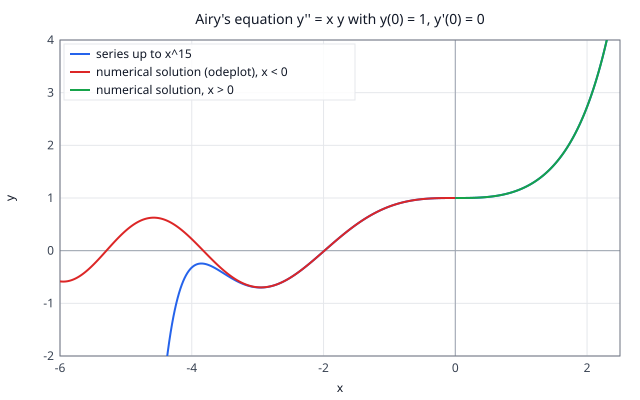

> `title`: A copy of plot p with a title or axis labels.

In [4]:
y0 = subs(subs(ai, a0, 1), a1, 0);
num1 = odeplot([v, x*u], [u v], x, [1 0], 0, -6, [x u]);
num2 = odeplot([v, x*u], [u v], x, [1 0], 0, 2.5, [x u]);
p = show(plot(y0, x, -6, 2.5), num1, num2);
p = window(p, -6, 2.5, -2, 4);
p = legend(p, "series up to x^15", "numerical solution (odeplot), x < 0", "numerical solution, x > 0");
labels(title(p, "Airy's equation y'' = x y with y(0) = 1, y'(0) = 0"), "x", "y")

The series and the numerical solution agree from about $x = -3$ to $2.5$; beyond $-3$ the fifteen terms are not
enough and the polynomial runs off. The series converges for every $x$, but far from 0 it needs many more terms. The
numerical solution shows the true behaviour: the oscillation keeps going, faster and slowly shrinking, as $x \to -\infty$.

**Try this.** From the recurrence, compute $a_3$, $a_6$ and $a_9$ when $a_0 = 1$, and check them in the output.

## 3. When the series stops: Hermite and Legendre polynomials

In the quantum harmonic oscillator the equation **Hermite's equation** $y'' - 2xy' + 2ny = 0$ appears. Its recurrence
is $a_{k+2} = \frac{2(k - n)}{(k + 2)(k + 1)}a_k$: when $k = n$ the factor $k - n$ is 0, and the series **stops**. For
$n = 3$ the odd series is a polynomial:

In [5]:
seriessolve(y'' - 2*x*y' + 6*y == 0, y, x, 8)
hermite(3, x)

a0*(x^8/280+x^6/30+x^4/2-3*x^2+1)+a1*(x-2*x^3/3)

> Power series y = a0 + a1 x + a2 x^2 + ... about x = 0: substitute it, collect powers of x and set each coefficient to zero. That gives a2 = -3*a0, a3 = -2*a1/3, a4 = a0/2, a5 = 0, and so on. a0 = y(0) and a1 = y'(0) stay free. The answer is exact up to x^8; the next terms are left out.

8*x^3-12*x

> `legendre`: Classical orthogonal polynomials of degree n: Legendre P_n, Hermite H_n (physicists'), Laguerre L_n, Chebyshev T_n and U_n.

$x - \tfrac23x^3$ is a multiple of the Hermite polynomial $H_3 = 8x^3 - 12x$. Physically, only the terminating
solutions stay finite (times $e^{-x^2/2}$) for large $|x|$, so only integer $n$ are allowed: this is why the energy of
a quantum oscillator is **quantized**, $E = (n + \tfrac12)\hbar\omega$.

Legendre's equation $(1 - x^2)y'' - 2xy' + \ell(\ell + 1)y = 0$ comes from the Laplace equation on a sphere (gravity,
electrostatics, the hydrogen atom). For $\ell = 3$:

In [6]:
seriessolve((1 - x^2)*y'' - 2*x*y' + 12*y == 0, y, x, 8)
legendre(3, x)

a0*(3*x^8/7+4*x^6/5+3*x^4-6*x^2+1)+a1*(x-5*x^3/3)

> Power series y = a0 + a1 x + a2 x^2 + ... about x = 0: substitute it, collect powers of x and set each coefficient to zero. That gives a2 = -6*a0, a3 = -5*a1/3, a4 = 3*a0, a5 = 0, and so on. a0 = y(0) and a1 = y'(0) stay free. The answer is exact up to x^8; the next terms are left out.

5*x^3/2-3*x/2

> `legendre`: Classical orthogonal polynomials of degree n: Legendre P_n, Hermite H_n (physicists'), Laguerre L_n, Chebyshev T_n and U_n.

The odd series stops at $x - \tfrac53x^3$, a multiple of $P_3 = \tfrac12(5x^3 - 3x)$. The even series goes on, and
diverges at $x = \pm1$, the poles of the sphere: again, only the polynomial is physical.

**Try this.** Which value of $\ell$ makes the even series of Legendre's equation stop after $x^2$? Check with
`seriessolve`.

## 4. How far does a series reach?

The series for $\cos x$ converges everywhere. Others do not: for $(1 + x^2)y'' + 2xy' = 0$ with $y(0) = 0$,
$y'(0) = 1$:

In [7]:
seriessolve((1 + x^2)*y'' + 2*x*y' == 0, y, x, 11, [0, 1])

-x^11/11+x^9/9-x^7/7+x^5/5-x^3/3+x

> Power series y = a0 + a1 x + a2 x^2 + ... about x = 0: substitute it, collect powers of x and set each coefficient to zero. That gives a2 = 0, a3 = -1/3, a4 = 0, a5 = 1/5, and so on. The answer is exact up to x^11; the next terms are left out.

That is $x - x^3/3 + x^5/5 - \cdots = \arctan x$, which converges only for $|x| \le 1$, even though $\arctan x$ is
perfectly smooth on the whole real line. The reason is in the complex plane: dividing by $1 + x^2$ gives coefficients
that blow up at $x = \pm i$, the **singular points**, at distance 1 from 0. In general:

> A power series solution about an ordinary point $x_0$ converges at least up to the nearest singular point, real or
> complex.

At a singular point itself, a power series may not exist. Bessel's equation $x^2y'' + xy' + (x^2 - \nu^2)y = 0$, for
vibrations of a drum, is singular at $x = 0$ (the coefficient of $y''$ vanishes there); there one tries
$y = x^r\sum a_nx^n$, the **Frobenius method**, and $r = \pm\nu$ comes out of an indicial equation like the
Cauchy–Euler equations of lesson 3. Galileo knows the result as `besselj(nu, x)`:

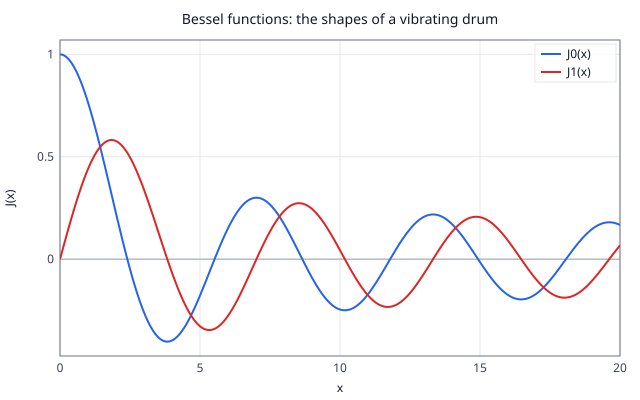

> `title`: A copy of plot p with a title or axis labels.

In [8]:
p = plot(besselj(0, x), besselj(1, x), x, 0, 20);
p = legend(p, "J0(x)", "J1(x)");
labels(title(p, "Bessel functions: the shapes of a vibrating drum"), "x", "J(x)")

**Try this.** What is the radius of convergence of the series solutions of $(4 - x^2)y'' + y = 0$ about $x = 0$?

## Summary

* Substitute $y = \sum a_nx^n$, collect powers of $x$, and get a recurrence; $a_0 = y(0)$ and $a_1 = y'(0)$ are
  free.
* The recurrence may produce known functions ($\cos$, $\sin$, $e^{x^2}$) or new ones (Airy).
* When a factor in the recurrence vanishes, the series stops: Hermite and Legendre polynomials, and quantization.
* The series converges up to the nearest singular point in the complex plane; at a singular point, use Frobenius.

Next: [Fourier series](07-fourier-series.ipynb), which expand in sines and cosines instead of powers.

## Exercises

1. **Recurrence.** Find the recurrence for $y'' + xy' + y = 0$ and show that with $y(0) = 1$, $y'(0) = 0$ the series
   is $e^{-x^2/2}$.
2. **Chebyshev.** Solve $(1 - x^2)y'' - xy' + 4y = 0$ by series. Which polynomial solution appears? Compare with
   `chebyshev(2, x)`.
3. **Radius.** Without computing, give the radius of convergence about $x = 0$ for $(x^2 + 2x + 2)y'' + y = 0$.
4. **Airy by hand.** Using the recurrence, write the first three nonzero terms of the solution of $y'' = xy$ with
   $y(0) = 0$, $y'(0) = 1$.
5. **Hermite.** Find the polynomial solution of $y'' - 2xy' + 8y = 0$ and compare with `hermite(4, x)`.

## Hints and answers

* **Section 1, Try this.** $1 + x^2 + x^4/2 + x^6/6 + x^8/24$, the Taylor series of $e^{x^2}$.
* **Section 2, Try this.** $a_3 = 1/6$, $a_6 = a_3/30 = 1/180$, $a_9 = a_6/72 = 1/12960$.
* **Section 3, Try this.** $\ell = 2$: $a_2 = -\ell(\ell + 1)a_0/2 = -3a_0$, $a_4 = 0$, giving $1 - 3x^2$, a multiple of
  $P_2 = (3x^2 - 1)/2$.
* **Section 4, Try this.** Singular points $x = \pm2$: radius 2.
* **Exercise 1.** $a_{n+2} = -a_n/(n + 2)$: $a_2 = -1/2$, $a_4 = 1/8$, $a_6 = -1/48$, the series of $e^{-x^2/2}$.
  `seriessolve(y'' + x*y' + y == 0, y, x, 8, [1, 0])`.
* **Exercise 2.** The even series stops: $1 - 2x^2$, which is $-T_2 = -(2x^2 - 1)$.
* **Exercise 3.** Roots $x = -1 \pm i$, at distance $\sqrt2$: radius $\sqrt2$.
* **Exercise 4.** $x + x^4/12 + x^7/504$.
* **Exercise 5.** $1 - 4x^2 + \tfrac43x^4$, a multiple of $H_4 = 16x^4 - 48x^2 + 12$.

## Sources

1. W. E. Boyce, R. C. DiPrima and D. B. Meade, *Elementary Differential Equations and Boundary Value Problems*, 11th
   ed., Wiley (2017), chapter 5.
2. G. B. Airy, "On the intensity of light in the neighbourhood of a caustic", *Transactions of the Cambridge
   Philosophical Society* 6 (1838) 379–402.
3. NIST *Digital Library of Mathematical Functions*, dlmf.nist.gov, chapters 9 (Airy), 10 (Bessel) and 18
   (orthogonal polynomials).
4. G. Frobenius, "Ueber die Integration der linearen Differentialgleichungen durch Reihen", *Journal für die reine und
   angewandte Mathematik* 76 (1873) 214–235.